In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib import cm
from IPython.display import HTML, display

Lx, Ly = 2.0, 1.0
Nx, Ny = 80, 40
hx, hy = Lx / Nx, Ly / Ny

x = np.linspace(0, Lx, Nx + 1)
y = np.linspace(0, Ly, Ny + 1)
X, Y = np.meshgrid(x, y)


In [2]:
def U_analytical(x, y):
    t1 = (3.0 / np.sinh(np.pi)) * np.sinh(np.pi * y) * np.sin(np.pi * x)
    t2 = (2.0 / np.sinh(6.0 * np.pi)) * np.sinh(3.0 * np.pi * x) * np.sin(3.0 * np.pi * y)
    return t1 + t2


In [ ]:
def solve_heat_explicit(Nx, Ny, Lx, Ly, dt=0.0001, tol=1e-6, max_iter=200000):
    hx, hy = Lx / Nx, Ly / Ny
    xg = np.linspace(0, Lx, Nx + 1)
    yg = np.linspace(0, Ly, Ny + 1)
    cx, cy = dt / hx**2, dt / hy**2

    U = np.zeros((Ny + 1, Nx + 1))
    U[:, -1] = 2.0 * np.sin(3.0 * np.pi * yg)
    U[-1, :] = 3.0 * np.sin(np.pi * xg)

    
    snapshots = [(0.0, U.copy())]

    for it in range(1, max_iter + 1):
        U_old = U.copy()

        # разностная схема
        U[1:Ny, 1:Nx] = U_old[1:Ny, 1:Nx] + cx * (U_old[1:Ny, 2:] - 2.0*U_old[1:Ny, 1:Nx] + U_old[1:Ny, 0:Nx-1]) \
                                          + cy * (U_old[2:, 1:Nx] - 2.0*U_old[1:Ny, 1:Nx] + U_old[0:Ny-1, 1:Nx])

        diff = np.max(np.abs(U - U_old))
        
        if it % 50 == 0:
            snapshots.append((it * dt, U.copy()))
            
        if diff < tol:
            snapshots.append((it * dt, U.copy()))
            print(f"сходимость: {it} итераций, t = {it*dt:.4f}, невязка {diff:.2e}")
            break

    return U, snapshots


сходимость: 4986 итераций, t = 0.4986, невязка 9.99e-08


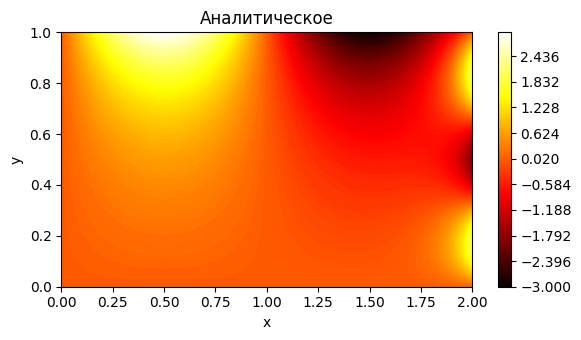

In [5]:
U_exact = U_analytical(X, Y)
U_num, snapshots = solve_heat_explicit(Nx, Ny, Lx, Ly, dt=0.0001, tol=1e-7)

plt.rcParams["animation.embed_limit"] = 80


n = len(snapshots)
if n > 200:
    s = n // 200
    idx = list(range(0, n, s))
    if idx[-1] != n - 1:
        idx.append(n - 1)
else:
    idx = list(range(n))
frames = [snapshots[i] for i in idx]

vmin = min(np.min(U_exact), min(np.min(f[1]) for f in frames))
vmax = max(np.max(U_exact), max(np.max(f[1]) for f in frames))
levels = np.linspace(vmin, vmax, 150)
fig, ax = plt.subplots(figsize=(6, 3.5))

def update(k):
    ax.cla()
    t_val, U_val = frames[k]
    ax.contourf(X, Y, U_val, levels=levels, cmap=cm.hot)
    ax.set_title(f"Численное (t = {t_val:.4f})")
    ax.set_xlabel("x")
    ax.set_ylabel("y")

anim = FuncAnimation(fig, update, frames=len(frames), interval=50, repeat=True)
plt.tight_layout()
plt.close(fig)
display(HTML(anim.to_jshtml()))

# аналитическое решение
fig2, ax2 = plt.subplots(figsize=(6, 3.5))
cf = ax2.contourf(X, Y, U_exact, levels=levels, cmap=cm.hot)
ax2.set_title("Аналитическое")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
fig2.colorbar(cf)
plt.tight_layout()
plt.show()
